In [35]:
pip install numpy pandas scikit-learn matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [36]:
#Import library
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [37]:
#Membuat 1000 Data Sintetik 2 Fitur
X, y = make_classification(
    n_samples=1000,
    n_features=2,
    n_informative=2,
    n_redundant=0,
    n_classes=2,
    n_clusters_per_class=1,
    class_sep=1.5,
    random_state=42
)

In [38]:
#Membuat DataFrame
df = pd.DataFrame(
    X,
    columns=['X1', 'X2']
)

df['Class'] = y

df.head()

,X1,X2,Class
0,1.101034,2.035353,1
1,1.255945,-1.672352,0
2,1.854479,-1.448528,0
3,3.603090,-0.266515,0
4,1.253178,1.287514,1


In [39]:
#Melihat Informasi Dataset
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   X1      1000 non-null   float64
 1   X2      1000 non-null   float64
 2   Class   1000 non-null   int64  
dtypes: float64(2), int64(1)
memory usage: 23.6 KB
None


In [40]:
#Statistik data
print(df.describe())

                X1           X2        Class
count  1000.000000  1000.000000  1000.000000
mean      1.525840    -0.012693     0.499000
std       1.071457     1.648874     0.500249
min      -1.972718    -3.350971     0.000000
25%       0.807209    -1.475712     0.000000
50%       1.523750    -0.106470     0.000000
75%       2.224713     1.469552     1.000000
max       4.638715     3.842864     1.000000


In [41]:
#Distribusi kelas
print(df['Class'].value_counts())

Class
0    501
1    499
Name: count, dtype: int64


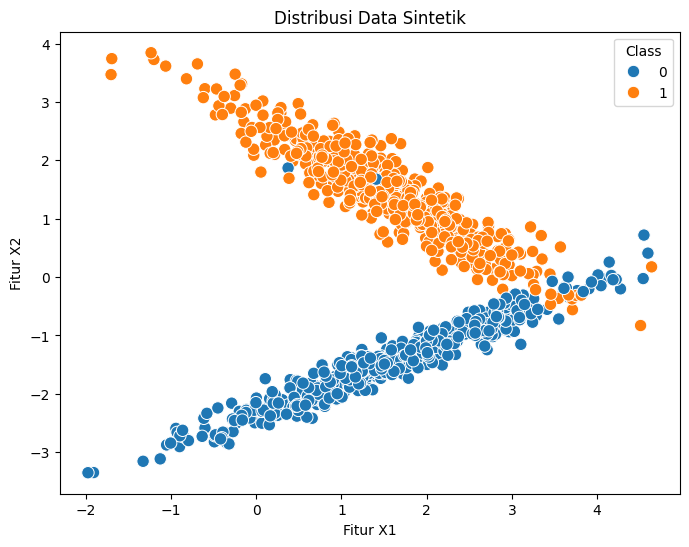

In [42]:
#Visualisasi
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x='X1',
    y='X2',
    hue='Class',
    s=80
)

plt.title('Distribusi Data Sintetik')
plt.xlabel('Fitur X1')
plt.ylabel('Fitur X2')
plt.show()

In [43]:
#Membagi Data Training dan Testing 80 20
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [44]:
#Cek jumlah data
print("Data training:", X_train.shape)
print("Data testing :", X_test.shape)

Data training: (800, 2)
Data testing : (200, 2)


In [45]:
#Standardisasi Data
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [46]:
#Membuat Model SVM Linear
svm_linear = SVC(
    kernel='linear',
    C=1.0
)

svm_linear.fit(
    X_train_scaled,
    y_train
)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide `.",False
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [47]:
#Melakukan prediksi
y_pred_linear = svm_linear.predict(
    X_test_scaled
)

In [48]:
#Evaluasi Model Akurasi
accuracy = accuracy_score(
    y_test,
    y_pred_linear
)

print("Accuracy:", accuracy)

Accuracy: 0.97


In [49]:
#Evaluasi Model Presisi
precision = precision_score(
    y_test,
    y_pred_linear
)

print("Precision:", precision)

Precision: 0.9795918367346939


In [50]:
#Evaluasi Model Recall
recall = recall_score(
    y_test,
    y_pred_linear
)

print("Recall:", recall)

Recall: 0.96


In [51]:
#Evaluasi Model F1-Score
f1 = f1_score(
    y_test,
    y_pred_linear
)

print("F1-Score:", f1)

F1-Score: 0.9696969696969697


In [52]:
#Klasifikasi Report
print(
    classification_report(
        y_test,
        y_pred_linear
    )
)

              precision    recall  f1-score   support

           0       0.96      0.98      0.97       100
           1       0.98      0.96      0.97       100

    accuracy                           0.97       200
   macro avg       0.97      0.97      0.97       200
weighted avg       0.97      0.97      0.97       200



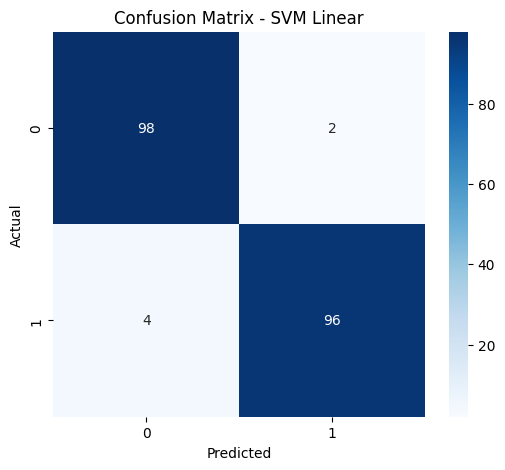

In [53]:
#Confusion Matrix
cm = confusion_matrix(
    y_test,
    y_pred_linear
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title('Confusion Matrix - SVM Linear')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

In [54]:
#Mencoba Kernel RBF
svm_rbf = SVC(
    kernel='rbf',
    C=1.0,
    gamma='scale'
)

svm_rbf.fit(
    X_train_scaled,
    y_train
)

y_pred_rbf = svm_rbf.predict(
    X_test_scaled
)

In [55]:
#evaluasi
print(
    classification_report(
        y_test,
        y_pred_rbf
    )
)

              precision    recall  f1-score   support

           0       0.96      0.99      0.98       100
           1       0.99      0.96      0.97       100

    accuracy                           0.97       200
   macro avg       0.98      0.97      0.97       200
weighted avg       0.98      0.97      0.97       200



In [56]:
# Kernel Polynomial
svm_poly = SVC(
    kernel='poly',
    degree=3,
    C=1.0
)

svm_poly.fit(
    X_train_scaled,
    y_train
)

y_pred_poly = svm_poly.predict(
    X_test_scaled
)

In [57]:
#evaluasi
print(
    classification_report(
        y_test,
        y_pred_poly
    )
)

              precision    recall  f1-score   support

           0       0.96      0.97      0.97       100
           1       0.97      0.96      0.96       100

    accuracy                           0.96       200
   macro avg       0.97      0.96      0.96       200
weighted avg       0.97      0.96      0.96       200



In [58]:
#Membandingkan Ketiga Kernel
models = {
    'Linear': y_pred_linear,
    'RBF': y_pred_rbf,
    'Polynomial': y_pred_poly
}

results = []

for name, prediction in models.items():

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(
            y_test,
            prediction
        ),
        'Precision': precision_score(
            y_test,
            prediction
        ),
        'Recall': recall_score(
            y_test,
            prediction
        ),
        'F1-Score': f1_score(
            y_test,
            prediction
        )
    })

results_df = pd.DataFrame(results)

print(results_df)

        Model  Accuracy  Precision  Recall  F1-Score
0      Linear     0.970   0.979592    0.96  0.969697
1         RBF     0.975   0.989691    0.96  0.974619
2  Polynomial     0.965   0.969697    0.96  0.964824


In [59]:
#Visualisasi Decision Boundary
def plot_decision_boundary(model, X, y, title):

    x_min = X[:, 0].min() - 1
    x_max = X[:, 0].max() + 1

    y_min = X[:, 1].min() - 1
    y_max = X[:, 1].max() + 1

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 500),
        np.linspace(y_min, y_max, 500)
    )

    Z = model.predict(
        np.c_[xx.ravel(), yy.ravel()]
    )

    Z = Z.reshape(xx.shape)

    plt.figure(figsize=(8, 6))

    plt.contourf(
        xx,
        yy,
        Z,
        alpha=0.3
    )

    plt.scatter(
        X[:, 0],
        X[:, 1],
        c=y,
        edgecolors='k',
        s=40
    )

    plt.title(title)
    plt.xlabel('X1')
    plt.ylabel('X2')

    plt.show()

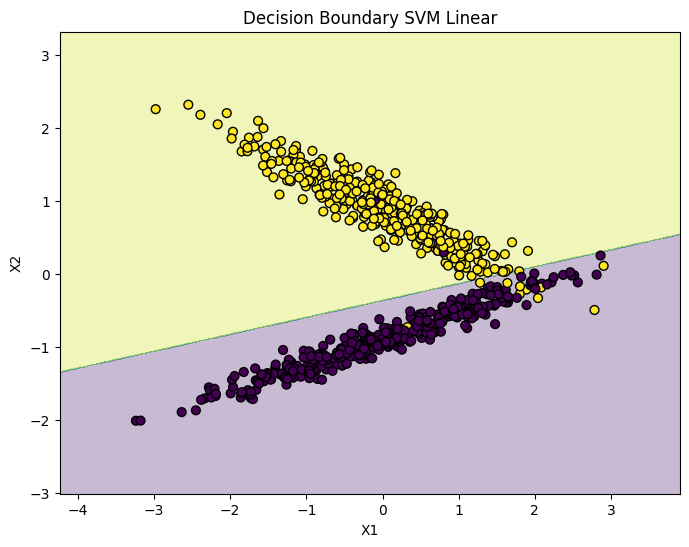

In [60]:
#pemanggilan fungsi visualiasi
plot_decision_boundary(
    svm_linear,
    X_train_scaled,
    y_train,
    'Decision Boundary SVM Linear'
)

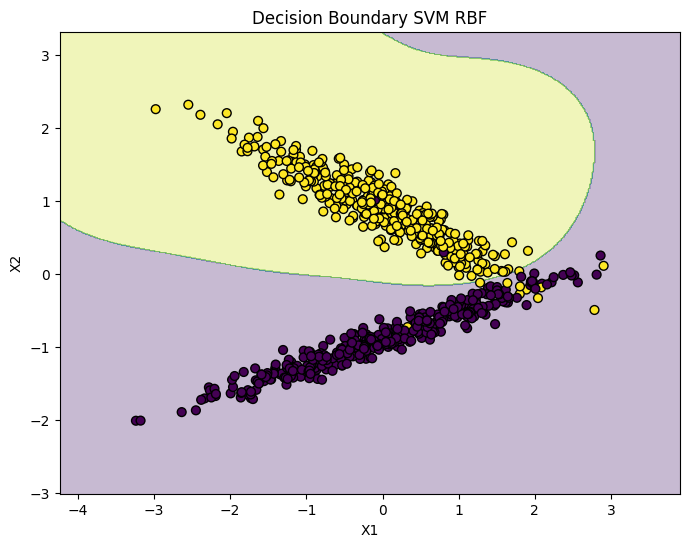

In [61]:
#visual plot rbf
plot_decision_boundary(
    svm_rbf,
    X_train_scaled,
    y_train,
    'Decision Boundary SVM RBF'
)

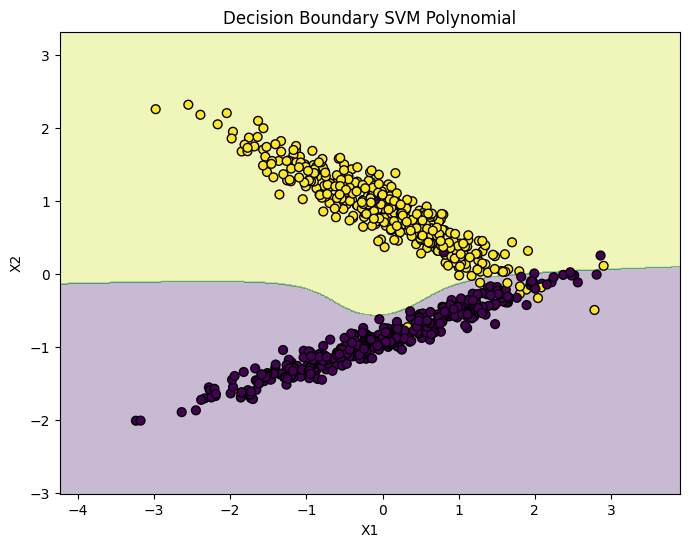

In [62]:
#visual plot poli
plot_decision_boundary(
    svm_poly,
    X_train_scaled,
    y_train,
    'Decision Boundary SVM Polynomial'
)

In [63]:
#Eksperimen Parameter C
C_values = [
    0.01,
    0.1,
    1,
    10,
    100
]

results_C = []

for c in C_values:

    model = SVC(
        kernel='rbf',
        C=c
    )

    model.fit(
        X_train_scaled,
        y_train
    )

    prediction = model.predict(
        X_test_scaled
    )

    results_C.append({
        'C': c,
        'Accuracy': accuracy_score(
            y_test,
            prediction
        ),
        'F1': f1_score(
            y_test,
            prediction
        )
    })

df_C = pd.DataFrame(results_C)

print(df_C)

        C  Accuracy        F1
0    0.01     0.960  0.958763
1    0.10     0.970  0.969388
2    1.00     0.975  0.974619
3   10.00     0.975  0.974619
4  100.00     0.980  0.979798


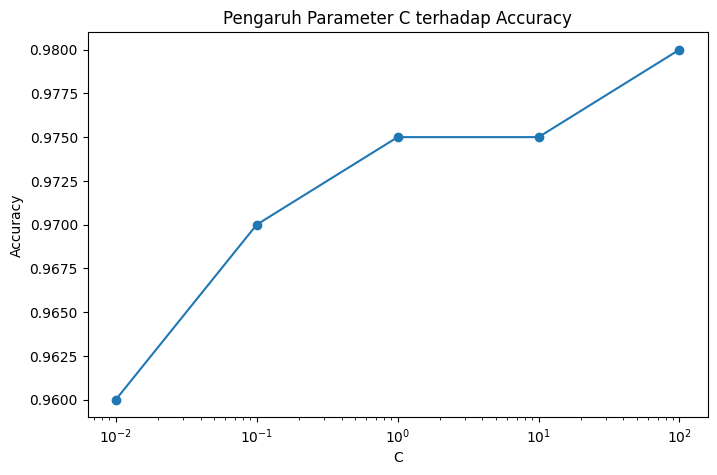

In [64]:
#visualisasai param C
plt.figure(figsize=(8, 5))

plt.plot(
    df_C['C'],
    df_C['Accuracy'],
    marker='o'
)

plt.xscale('log')

plt.xlabel('C')
plt.ylabel('Accuracy')

plt.title(
    'Pengaruh Parameter C terhadap Accuracy'
)

plt.show()

In [65]:
#Eksperimen Gamma kernel rbf
gamma_values = [
    0.001,
    0.01,
    0.1,
    1,
    10
]

results_gamma = []

for gamma in gamma_values:

    model = SVC(
        kernel='rbf',
        C=1.0,
        gamma=gamma
    )

    model.fit(
        X_train_scaled,
        y_train
    )

    prediction = model.predict(
        X_test_scaled
    )

    results_gamma.append({
        'Gamma': gamma,
        'Accuracy': accuracy_score(
            y_test,
            prediction
        ),
        'F1': f1_score(
            y_test,
            prediction
        )
    })

df_gamma = pd.DataFrame(results_gamma)

print(df_gamma)

    Gamma  Accuracy        F1
0   0.001     0.955  0.953846
1   0.010     0.960  0.958763
2   0.100     0.970  0.969388
3   1.000     0.975  0.974619
4  10.000     0.980  0.979798


In [66]:
#ALUR PROJECT